In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn import linear_model
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multiclass import OneVsOneClassifier
from sklearn.metrics import ConfusionMatrixDisplay

df = pd.read_csv("Airline Quality Ratings.csv")

In [3]:
df = df.drop(columns=[
    'ID', 
    'Gender', 
    'Age', 
    'Customer Type', 
    'Flight Distance', 
    'Departure Delay', 
    'Arrival Delay', 
    'Ease of Online Booking', 
    'Check-in Service', 
    'Online Boarding', 
    'Gate Location', 
    'Baggage Handling',
    'Type of Travel',
    'Class'

])
df.info()
df = df.dropna(how = 'any')
df.value_counts

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 10 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   Departure and Arrival Time Convenience  129880 non-null  int64
 1   On-board Service                        129880 non-null  int64
 2   Seat Comfort                            129880 non-null  int64
 3   Leg Room Service                        129880 non-null  int64
 4   Cleanliness                             129880 non-null  int64
 5   Food and Drink                          129880 non-null  int64
 6   In-flight Service                       129880 non-null  int64
 7   In-flight Wifi Service                  129880 non-null  int64
 8   In-flight Entertainment                 129880 non-null  int64
 9   Satisfaction                            129880 non-null  str  
dtypes: int64(9), str(1)
memory usage: 9.9 MB


<bound method DataFrame.value_counts of         Departure and Arrival Time Convenience  On-board Service  \
0                                            3                 3   
1                                            2                 5   
2                                            4                 3   
3                                            2                 5   
4                                            3                 3   
...                                        ...               ...   
129875                                       4                 5   
129876                                       5                 5   
129877                                       5                 3   
129878                                       4                 4   
129879                                       1                 4   

        Seat Comfort  Leg Room Service  Cleanliness  Food and Drink  \
0                  5                 2            5               5   
1

In [4]:
df.info()

df = df.dropna(how = 'any')

df.value_counts()

###Changing Variables to Binary

df.replace({"Satisfied":1, "Neutral or Dissatisfied":0}, inplace = True)

#Test

'''print(df['Satisfaction'])'''

'''

df.replace({'Business':1, 'Economy':0, 'Economy Plus':1},inplace = True)

print(df['Class'])'''

###Average satisfaction rate

Average_satisfaction_rate = len(df[df['Satisfaction'] == 1]) / len(df['Satisfaction']) * 100

print(Average_satisfaction_rate, '%')

ASR_Deptime = len(df[(df['Departure and Arrival Time Convenience'] > 2) & (df['Satisfaction'] == 1)]) / len(df['Satisfaction']) * 100

print(ASR_Deptime, '%')

ASR_Onboard = len(df[(df['On-board Service'] > 3) & (df['Satisfaction'] == 1)]) / len(df['Satisfaction']) * 100

print(ASR_Onboard, '%')

ASR_Seat = len(df[(df['Seat Comfort'] > 3) & (df['Satisfaction'] == 1)]) / len(df['Satisfaction']) * 100

print(ASR_Seat, '%')

ASR_LegRoom = len(df[(df['Leg Room Service'] > 3) & (df['Satisfaction'] == 1)]) / len(df['Satisfaction']) * 100

print(ASR_LegRoom, '%')

ASR_Cleanliness = len(df[(df['Cleanliness'] > 3) & (df['Satisfaction'] == 1)]) / len(df['Satisfaction']) * 100

print(ASR_Cleanliness, '%')

ASR_FoodDrink = len(df[(df['Food and Drink'] > 3) & (df['Satisfaction'] == 1)]) / len(df['Satisfaction']) * 100

print(ASR_FoodDrink, '%')

ASR_InflightService = len(df[(df['In-flight Service'] > 3) & (df['Satisfaction'] == 1)]) / len(df['Satisfaction']) * 100

print(ASR_InflightService, '%')

ASR_Wifi = len(df[(df['In-flight Wifi Service'] > 3) & (df['Satisfaction'] == 1)]) / len(df['Satisfaction']) * 100

print(ASR_Wifi, '%')

ASR_Entertainment = len(df[(df['In-flight Entertainment'] > 3) & (df['Satisfaction'] == 1)]) / len(df['Satisfaction']) * 100

print(ASR_Entertainment, '%')


<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 10 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   Departure and Arrival Time Convenience  129880 non-null  int64
 1   On-board Service                        129880 non-null  int64
 2   Seat Comfort                            129880 non-null  int64
 3   Leg Room Service                        129880 non-null  int64
 4   Cleanliness                             129880 non-null  int64
 5   Food and Drink                          129880 non-null  int64
 6   In-flight Service                       129880 non-null  int64
 7   In-flight Wifi Service                  129880 non-null  int64
 8   In-flight Entertainment                 129880 non-null  int64
 9   Satisfaction                            129880 non-null  str  
dtypes: int64(9), str(1)
memory usage: 9.9 MB
43.44625808438558 %
26.269633507853403

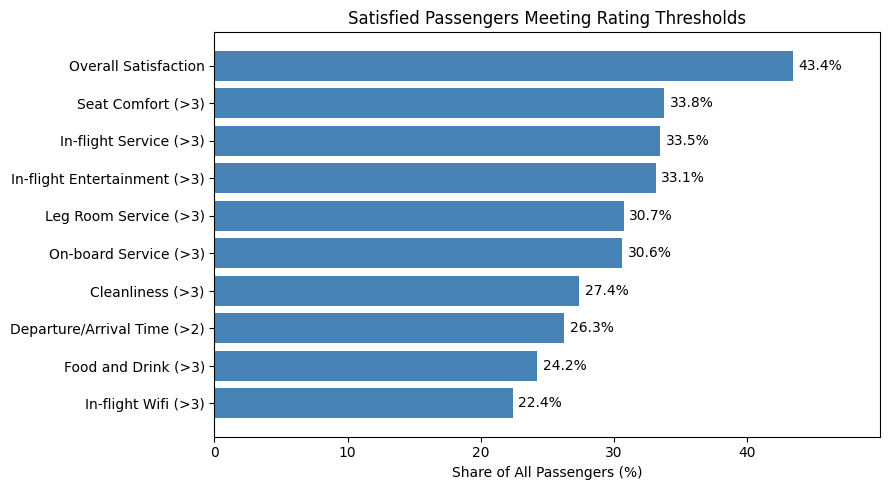

In [5]:
###Plots

rates = {
    "Overall Satisfaction": Average_satisfaction_rate,
    "Departure/Arrival Time (>2)": ASR_Deptime,
    "On-board Service (>3)": ASR_Onboard,
    "Seat Comfort (>3)": ASR_Seat,
    "Leg Room Service (>3)": ASR_LegRoom,
    "Cleanliness (>3)": ASR_Cleanliness,
    "Food and Drink (>3)": ASR_FoodDrink,
    "In-flight Service (>3)": ASR_InflightService,
    "In-flight Wifi (>3)": ASR_Wifi,
    "In-flight Entertainment (>3)": ASR_Entertainment,
}

# Sort from lowest to highest for easier reading
rates_series = pd.Series(rates).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(rates_series.index, rates_series.values, color="steelblue")

ax.set_xlabel("Share of All Passengers (%)")
ax.set_title("Satisfied Passengers Meeting Rating Thresholds")
ax.set_xlim(0, max(rates_series.values) * 1.15)
ax.bar_label(bars, fmt="%.1f%%", padding=4)

plt.tight_layout()
plt.show()

In [6]:
x = df[['Departure and Arrival Time Convenience',
    'On-board Service',
    'Seat Comfort',
    'Leg Room Service',
    'Cleanliness',
    'Food and Drink',
    'In-flight Service',
    'In-flight Wifi Service',
    'In-flight Entertainment']].to_numpy()
y = df['Satisfaction'].map({"Satisfied": 1, "Neutral or Dissatisfied": 0}).astype(int).to_numpy()

X_train, X_test, y_train, y_test = train_test_split(x,y,train_size=0.8,random_state=42)

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer.Replace or remove non-finite values or cast to an integer typethat supports these values (e.g. 'Int64')

0.7691638435478904


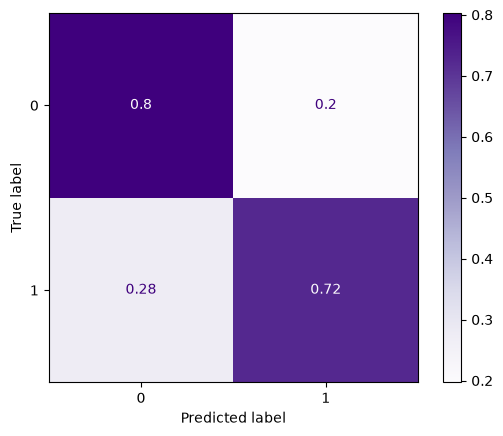

In [ ]:
ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000,C=np.inf)).fit(x, y)
print(ovr.score(x,y))
ConfusionMatrixDisplay.from_estimator(ovr,x,y,normalize='true', cmap='Purples')
plt.show()

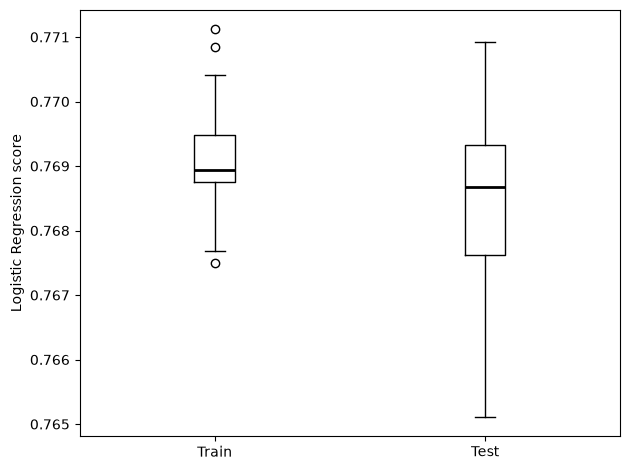

0.7689460600994324
0.7686710809978441


In [ ]:
n_trials = 50
score_tv = list()
score_te = list()
splits = ShuffleSplit(n_splits=n_trials, train_size=0.7, random_state=42)
for train, test in splits.split(x):
    x_tv,y_tv = x[train], y[train]
    x_te,y_te = x[test], y[test]

    ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000,C=np.inf)).fit(x_tv, y_tv)
    score_tv.append(ovr.score(x_tv,y_tv))
    score_te.append(ovr.score(x_te,y_te))

plt.boxplot([score_tv,score_te],medianprops=dict(color='k', linewidth=2))
plt.ylabel('Logistic Regression score')
plt.xticks([1,2],labels=['Train','Test'])
plt.tight_layout()
plt.show()

print(np.median(score_tv))
print(np.median(score_te))

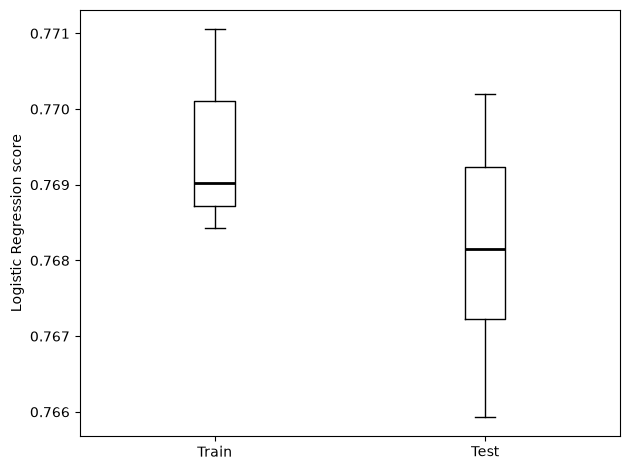

0.7690175546658454
0.7681577866748793


In [ ]:
## Stratification splits

n_trials = 10
score_tv = list()
score_te = list()
split = StratifiedShuffleSplit(n_splits=n_trials, train_size=0.7,random_state=42)
for train, test in split.split(x, y):
    x_tv,y_tv = x[train], y[train]
    x_te,y_te = x[test], y[test]

    ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000,C=np.inf)).fit(x_tv, y_tv)
    score_tv.append(ovr.score(x_tv,y_tv))
    score_te.append(ovr.score(x_te,y_te))

plt.boxplot([score_tv,score_te],medianprops=dict(color='k', linewidth=2))
plt.ylabel('Logistic Regression score')
plt.xticks([1,2],labels=['Train','Test'])
plt.tight_layout()
plt.show()

print(np.median(score_tv))
print(np.median(score_te))

In [ ]:
ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000))
ovo = OneVsOneClassifier(LogisticRegression(max_iter=1000))
models = [ovr,ovo]

param_grid = {'estimator__C': np.logspace(-4,3,num=8)}

n_outer_splits = 5
n_repeats = 5
n_inner_splits = 8

test_scores = np.zeros((n_outer_splits*n_repeats,len(models)))
model_choice = np.zeros(n_outer_splits*n_repeats)
param_choice = np.zeros(n_outer_splits*n_repeats)

outercv = RepeatedStratifiedKFold(n_splits=n_outer_splits,n_repeats=n_repeats,random_state=42)
innercv = StratifiedKFold(n_splits=n_inner_splits,shuffle=True,random_state=42)

for k, (train, test) in enumerate(outercv.split(x,y)):
    x_tv,y_tv = x[train], y[train]
    x_te,y_te = x[test], y[test]

    estimators = list()
    scores = list()
    param = list()
    for model in models:
        param_cv = GridSearchCV(model,param_grid,n_jobs=4,cv=innercv)
        param_cv.fit(x_tv,y_tv)
        scores.append(param_cv.best_score_)
        estimators.append(param_cv.best_estimator_)
        param.append(param_cv.best_params_['estimator__C'])

    choose = int(np.argmax(scores))
    model_choice[k] = choose
    param_choice[k] = param[choose]
    for j, model in enumerate(estimators):
        model.fit(x_tv,y_tv)
        test_scores[k,j] = model.score(x_te,y_te)

print(np.mean(model_choice))
print(np.mean(test_scores[:,0]-test_scores[:,1]))

0.0
0.0
